# PoC: predicción de reingreso hospitalario antes de 30 días
**Lucas Didone · Primera entrega · 2 de octubre de 2026**  
Fundamentos de Medicina y Aplicaciones de Inteligencia Artificial

**Objetivo:** determinar si las variables disponibles al alta aportan señal predictiva útil para priorizar seguimiento en una cohorte pública histórica de pacientes con diabetes. Esta PoC evalúa factibilidad técnica retrospectiva, no eficacia clínica.

**Endpoint:** `readmitted == '<30'` frente a `'>30'` o `'NO'`. Reingreso registrado de cualquier causa, no necesariamente recaída de diabetes ni evento evitable. La observación incompleta fuera de la red y al final del período limita la etiqueta negativa.

**Unidad:** internación elegible. Un paciente puede tener varias internaciones, siempre en la misma partición. La interpretación operativa es capacidad de seguimiento por episodio de alta, no cantidad de personas únicas.

**Cómo ejecutar:** Python 3.12 y dependencias de `requirements.txt`. Abrir desde la carpeta del proyecto y ejecutar todas las celdas. El ZIP incluye los datos públicos para uso sin conexión. Si faltan, la celda de descarga los obtiene de UCI. CPU, sin GPU ni API de pago.

## 1. Protocolo fijado antes de evaluar el test
- Cohorte de **20 años o más** (los intervalos de edad impiden aislar 18–19 años). Excluir fallecimiento, hospice y sexo registrado como inválido.
- Partición aleatoria por paciente: aproximadamente 60 % entrenamiento, 20 % validación y 20 % test. No es una validación temporal ni externa.
- Ajustar limpieza aprendida, imputación y codificación únicamente con entrenamiento.
- Comparar prevalencia constante, regresión logística y gradient boosting. Elegir LR o boosting por **Average Precision (AP)** de validación, sin ajustar con test. AP resume la curva precision–recall, sin interpolación trapezoidal.
- Referencia operativa: seleccionar el 20 % de episodios. Reportar precision, recall y lift sobre selección aleatoria. Un umbral 0,5 y accuracy pueden ocultar la señal por desbalance.
- **Criterio exploratorio de continuidad:** AP/prevalencia ≥ 1,5; lift@20 % ≥ 1,5; límite inferior del IC95 % de AP−prevalencia > 0 y de AUROC > 0,5. Son umbrales académicos elegidos para esta PoC, no estándares clínicos.
- Control negativo con etiquetas de entrenamiento permutadas y ablación del historial de utilización en validación. Test reservado para evaluación final del modelo congelado.
- IC95 % mediante 300 remuestreos de pacientes completos. Evalúan incertidumbre del conjunto test, condicionada al modelo entrenado.

In [1]:
import os
os.environ.setdefault('OMP_NUM_THREADS', '4')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '4')
from pathlib import Path
import sys, json, hashlib, zipfile, urllib.request, time, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss,
                             precision_recall_curve, roc_curve, confusion_matrix)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from threadpoolctl import threadpool_limits
threadpool_limits(limits=4)
SEED = 42
BASE = Path.cwd()
DATA = BASE / 'data'; OUT = BASE / 'output'
DATA.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})
versions = {'python': platform.python_version(), 'numpy': np.__version__,
            'pandas': pd.__version__, 'scikit-learn': sklearn.__version__}
print(versions)

{'python': '3.12.14', 'numpy': '2.3.5', 'pandas': '2.2.3', 'scikit-learn': '1.8.0'}


## 2. Fuente y lectura
Fuente: Clore, Cios, DeShazo y Strack (2014), *Diabetes 130-US Hospitals for Years 1999–2008*, UCI. DOI: https://doi.org/10.24432/C5230J. Licencia CC BY 4.0. Consulta/descarga: 02/10/2026.

El archivo contiene 101.766 episodios y 50 columnas, incluidos identificadores y outcome. `?` indica faltante. **No convertir la cadena `None` a NaN:** en HbA1c y glucemia identifica que no se realizó la prueba.

In [2]:
URL = 'https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip'
archive = DATA / 'diabetes.zip'
if not archive.exists():
    urllib.request.urlretrieve(URL, archive)
sha256 = hashlib.sha256(archive.read_bytes()).hexdigest()
with zipfile.ZipFile(archive) as z:
    with z.open('diabetic_data.csv') as f:
        raw = pd.read_csv(f, keep_default_na=False, na_values=['?'], low_memory=False)
    mapping_text = z.read('IDS_mapping.csv').decode('utf-8')
assert raw.encounter_id.is_unique
assert set(raw.readmitted.unique()) == {'<30', '>30', 'NO'}
print('SHA256 del ZIP:', sha256)
print('Filas, columnas:', raw.shape, '| Pacientes únicos:', raw.patient_nbr.nunique())
display(raw.readmitted.value_counts().rename('Episodios').to_frame())
display(raw.isna().mean().sort_values(ascending=False).head(8).rename('Fracción faltante').to_frame())

SHA256 del ZIP: f82ac129da2ddd2299391ff6fbae3a6a58b3edcf59ac9d7bd480c00fe453112a
Filas, columnas: (101766, 50) | Pacientes únicos: 71518


,Episodios
readmitted,
NO,54864
>30,35545
<30,11357


,Fracción faltante
weight,0.968585
medical_specialty,0.490822
payer_code,0.395574
race,0.022336
diag_3,0.013983
diag_2,0.003518
diag_1,0.000206
admission_type_id,0.000000


## 3. Cohorte y disponibilidad de variables
Según `IDS_mapping.csv`, se excluyen destinos 11, 19, 20, 21 (fallecimiento) y 13, 14 (hospice). Las exclusiones se cuentan secuencialmente, sin doble conteo.

El modelo predice **al alta**, por lo que puede usar duración de la estancia, pruebas, diagnósticos codificados y medicación registrados durante la internación. En implementación futura debe confirmarse que cada campo esté realmente disponible en ese momento. No se propone usar este modelo al ingreso.

La cohorte principal conserva transferencias y destinos desconocidos. Se evaluará aparte el subconjunto de altas a domicilio para explorar cuánto cambia el desempeño en una población más cercana al caso de uso. No se redefinirá la cohorte después de mirar los resultados.

In [3]:
cohort = raw.copy()
flow = [{'etapa': 'Datos originales', 'episodios': len(cohort), 'excluidos': 0}]
for name, keep in [
    ('Edad ≥20 años', lambda d: ~d.age.isin(['[0-10)', '[10-20)'])),
    ('Sin fallecimiento ni hospice', lambda d: ~d.discharge_disposition_id.isin([11,13,14,19,20,21])),
    ('Sexo registrado válido', lambda d: d.gender != 'Unknown/Invalid')]:
    n0 = len(cohort)
    cohort = cohort.loc[keep(cohort)].copy()
    flow.append({'etapa': name, 'episodios': len(cohort), 'excluidos': n0-len(cohort)})
cohort = cohort.reset_index(drop=True)
y = cohort.readmitted.eq('<30').astype(int)
groups = cohort.patient_nbr
print('Prevalencia de la cohorte:', f'{y.mean():.2%}')
display(pd.DataFrame(flow))

Prevalencia de la cohorte: 11.44%


,etapa,episodios,excluidos
0,Datos originales,101766,0
1,Edad ≥20 años,100914,852
2,Sin fallecimiento ni hospice,98493,2421
3,Sexo registrado válido,98490,3


In [4]:
# Se generan los índices sin usar el outcome y se verifica disjunción por paciente.
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
dev_idx, test_idx = next(gss.split(cohort, groups=groups))
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED+1)
tr_local, va_local = next(gss2.split(cohort.iloc[dev_idx], groups=groups.iloc[dev_idx]))
train_idx, val_idx = dev_idx[tr_local], dev_idx[va_local]
parts = {'train': train_idx, 'validation': val_idx, 'test': test_idx}
for a, b in [('train','validation'), ('train','test'), ('validation','test')]:
    assert set(groups.iloc[parts[a]]).isdisjoint(groups.iloc[parts[b]])
assert len(train_idx) + len(val_idx) + len(test_idx) == len(cohort)
print('Pacientes compartidos entre particiones: 0')
# Las métricas de test se consultan recién después de elegir el modelo.
display(pd.DataFrame([{'partición': k, 'episodios': len(ix),
                      'pacientes': groups.iloc[ix].nunique()}
                     for k,ix in parts.items()]))

Pacientes compartidos entre particiones: 0


,partición,episodios,pacientes
0,train,58870,41586
1,validation,19849,13862
2,test,19771,13863


In [5]:
excluded = ['encounter_id','patient_nbr','readmitted','race','payer_code']
# Race y payer_code quedan fuera del predictor en esta PoC. Esto no garantiza equidad.
X = cohort.drop(columns=excluded).copy()
for c in ['admission_type_id','discharge_disposition_id','admission_source_id']:
    X[c] = X[c].astype(str)  # códigos nominales, no magnitudes
train_missing = X.iloc[train_idx].isna().mean()
dropped_missing = train_missing[train_missing > 0.80].index.tolist()
constant = [c for c in X if X.iloc[train_idx][c].nunique(dropna=False) <= 1]
dropped = sorted(set(dropped_missing + constant))
X = X.drop(columns=dropped)
num = X.select_dtypes(include='number').columns.tolist()
cat = [c for c in X if c not in num]
Xtr, Xva, Xte = X.iloc[train_idx], X.iloc[val_idx], X.iloc[test_idx]
ytr, yva, yte = y.iloc[train_idx], y.iloc[val_idx], y.iloc[test_idx]
print('Exclusiones por faltantes/constancia aprendidas en train:', dropped)
print(f'Features finales: {X.shape[1]} ({len(num)} numéricas, {len(cat)} categóricas)')
display(pd.DataFrame({'variable': X.columns,
                      'tipo': ['numérica' if c in num else 'categórica' for c in X.columns],
                      'faltante_train': [float(Xtr[c].isna().mean()) for c in X.columns]}))

Exclusiones por faltantes/constancia aprendidas en train: ['citoglipton', 'examide', 'weight']
Features finales: 42 (8 numéricas, 34 categóricas)


,variable,tipo,faltante_train
0,gender,categórica,0.000000
1,age,categórica,0.000000
2,admission_type_id,categórica,0.000000
3,discharge_disposition_id,categórica,0.000000
4,admission_source_id,categórica,0.000000
5,time_in_hospital,numérica,0.000000
6,medical_specialty,categórica,0.490505
7,num_lab_procedures,numérica,0.000000
8,num_procedures,numérica,0.000000
9,num_medications,numérica,0.000000


## 4. Modelos y métricas
Configuraciones pequeñas y fijas, sin búsqueda masiva. No se usa SMOTE ni ponderación de clases: se evalúan scores y probabilidades bajo la prevalencia observada.

La regresión logística usa imputación, escalado y one-hot con agrupación de categorías infrecuentes. El boosting usa codificación ordinal **marcada explícitamente como categórica**, sin imponer un orden a los códigos. Se desactiva early stopping para evitar una partición interna por filas. Todos los transformadores se ajustan exclusivamente en train.

En los rankings, los empates se resuelven aleatoriamente con semilla fija. Para la referencia aleatoria se reporta también la expectativa analítica: precision = prevalencia, recall = fracción seleccionada, lift = 1.

In [6]:
def make_model(kind, columns):
    nc = [c for c in columns if c in num]
    cc = [c for c in columns if c in cat]
    if kind == 'LR':
        prep = ColumnTransformer([
            ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                              ('scale', StandardScaler())]), nc),
            ('cat', Pipeline([('impute', SimpleImputer(strategy='constant', fill_value='Missing')),
                              ('encode', OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                      min_frequency=30, max_categories=64))]), cc)])
        model = LogisticRegression(C=1.0, solver='lbfgs', max_iter=1000, random_state=SEED)
    else:
        prep = ColumnTransformer([
            ('num', SimpleImputer(strategy='median'), nc),
            ('cat', Pipeline([('impute', SimpleImputer(strategy='constant', fill_value='Missing')),
                              ('encode', OrdinalEncoder(handle_unknown='use_encoded_value',
                                 unknown_value=-1, min_frequency=30, max_categories=64))]), cc)])
        model = HistGradientBoostingClassifier(
            max_iter=180, learning_rate=0.07, max_leaf_nodes=15, min_samples_leaf=40,
            l2_regularization=5.0, early_stopping=False,
            categorical_features=list(range(len(nc), len(nc)+len(cc))), random_state=SEED)
    return Pipeline([('prep', prep), ('model', model)])

def top_metrics(yt, prob, q=0.20):
    yt, prob = np.asarray(yt), np.asarray(prob)
    k = max(1, int(np.ceil(q*len(yt))))
    tie = np.random.default_rng(SEED).random(len(yt))
    chosen = np.lexsort((tie, -prob))[:k]
    tp = int(yt[chosen].sum()); total = int(yt.sum())
    return {'selected': k, 'tp': tp, 'fp': k-tp, 'fn': total-tp,
            'precision': tp/k, 'recall': tp/total,
            'lift': (tp/k)/yt.mean(), 'fraction': k/len(yt)}

def metrics(yt, prob):
    m = top_metrics(yt,prob)
    return {'AUROC': roc_auc_score(yt,prob), 'AP': average_precision_score(yt,prob),
            'Brier': brier_score_loss(yt,prob), 'Precision@20': m['precision'],
            'Recall@20': m['recall'], 'Lift@20': m['lift']}

models, validation_scores, fit_seconds = {}, {}, {}
for name, kind in [('Logística','LR'), ('Gradient boosting','HGB')]:
    t0 = time.perf_counter()
    models[name] = make_model(kind, X.columns).fit(Xtr,ytr)
    fit_seconds[name] = time.perf_counter()-t0
    validation_scores[name] = metrics(yva, models[name].predict_proba(Xva)[:,1])
prior = np.full(len(yva), ytr.mean())
validation_scores['Prevalencia constante'] = metrics(yva, prior)
val_table = pd.DataFrame(validation_scores).T
selected_name = max(models, key=lambda n: validation_scores[n]['AP'])
best = models[selected_name]
print('Modelo elegido por AP de validación:', selected_name)
print('Tiempo de ajuste (segundos):', fit_seconds)
display(val_table.round(4))

Modelo elegido por AP de validación: Logística
Tiempo de ajuste (segundos): {'Logística': 1.734280513000158, 'Gradient boosting': 1.9234485869997116}


,AUROC,AP,Brier,Precision@20,Recall@20,Lift@20
Logística,0.6533,0.2194,0.0965,0.2081,0.3665,1.8322
Gradient boosting,0.6563,0.2163,0.0967,0.2108,0.3713,1.8566
Prevalencia constante,0.5000,0.1136,0.1007,0.1108,0.1952,0.9760


## 5. ¿Qué señal aportan las features? Diagnósticos en validación
Dos ablaciones: usar únicamente utilización previa (`number_inpatient`, `number_emergency`, `number_outpatient`) y retirarla del boosting. El control negativo permuta las etiquetas de entrenamiento manteniendo el dataset de validación intacto. Estos diagnósticos no participan en la selección entre LR y boosting y no usan test.

La importancia por permutación mide cuánto cae AP al desordenar una columna en validación. Es asociación predictiva, no causalidad. Variables correlacionadas pueden repartirse u ocultar importancia.

,AUROC,AP,Brier,Precision@20,Recall@20,Lift@20
Solo utilización previa (LR),0.6055,0.1860,0.0980,0.1887,0.3323,1.6614
Sin utilización previa (HGB),0.6208,0.1790,0.0987,0.1776,0.3128,1.5638
Etiquetas permutadas (HGB),0.5068,0.1191,0.1015,0.1244,0.2192,1.0958
Modelo seleccionado,0.6533,0.2194,0.0965,0.2081,0.3665,1.8322


,feature,drop_AP,sd
12,number_inpatient,0.0544,0.0052
3,discharge_disposition_id,0.0211,0.0037
14,diag_2,0.0070,0.0014
13,diag_1,0.0036,0.0013
41,diabetesMed,0.0022,0.0004
1,age,0.0018,0.0009
6,medical_specialty,0.0013,0.0015
9,num_medications,0.0007,0.0007
23,glimepiride,0.0007,0.0001
2,admission_type_id,0.0007,0.0009


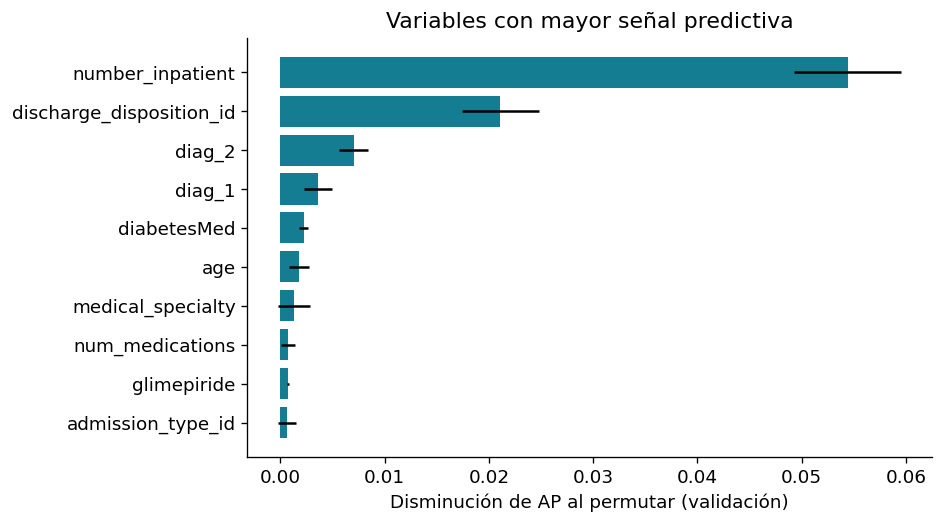

In [7]:
history = ['number_inpatient','number_emergency','number_outpatient']
only_history = make_model('LR', history).fit(Xtr[history],ytr)
nohistory_cols = [c for c in X if c not in history]
no_history = make_model('HGB', nohistory_cols).fit(Xtr[nohistory_cols],ytr)
negative = make_model('HGB', X.columns).fit(Xtr, np.random.default_rng(SEED).permutation(ytr))
diagnostics = {
 'Solo utilización previa (LR)': metrics(yva, only_history.predict_proba(Xva[history])[:,1]),
 'Sin utilización previa (HGB)': metrics(yva, no_history.predict_proba(Xva[nohistory_cols])[:,1]),
 'Etiquetas permutadas (HGB)': metrics(yva, negative.predict_proba(Xva)[:,1]),
 'Modelo seleccionado': validation_scores[selected_name]
}
display(pd.DataFrame(diagnostics).T.round(4))
# Muestra fija de validación para mantener la PoC liviana.
rng = np.random.default_rng(SEED)
sample = rng.choice(len(Xva), size=min(5000,len(Xva)), replace=False)
imp = permutation_importance(best, Xva.iloc[sample], yva.iloc[sample],
                            scoring='average_precision', n_repeats=3,
                            random_state=SEED, n_jobs=1)
importance = pd.DataFrame({'feature': X.columns, 'drop_AP': imp.importances_mean,
                          'sd': imp.importances_std}).sort_values('drop_AP',ascending=False)
display(importance.head(12).round(4))
fig, ax = plt.subplots(figsize=(8,4.5))
v = importance.head(10).iloc[::-1]
ax.barh(v.feature, v.drop_AP, xerr=v.sd, color='#147D92')
ax.set_xlabel('Disminución de AP al permutar (validación)')
ax.set_title('Variables con mayor señal predictiva')
fig.tight_layout(); fig.savefig(OUT/'importancia.png', dpi=170); plt.show()

## 6. Evaluación final sobre test reservado
A partir de aquí el modelo queda congelado: ninguna decisión de entrenamiento depende de estos resultados. No se reentrena sobre train+validación, para que la evaluación corresponda exactamente al modelo seleccionado.

La comparación principal es contra selección aleatoria y prevalencia. La logística y la regla de utilización previa aportan referencias adicionales. La factibilidad no exige que un modelo complejo supere siempre a uno simple.

In [8]:
test_probs = {name: model.predict_proba(Xte)[:,1] for name,model in models.items()}
test_probs['Prevalencia constante'] = np.full(len(yte),ytr.mean())
test_probs['Solo utilización previa (LR)'] = only_history.predict_proba(Xte[history])[:,1]
test_scores = {name: metrics(yte,p) for name,p in test_probs.items()}
test_table = pd.DataFrame(test_scores).T
pbest = test_probs[selected_name]
print(f'Prevalencia test: {yte.mean():.2%}; episodios: {len(yte):,}; positivos: {yte.sum():,}')
display(test_table.round(4))
capacity = pd.DataFrame([{'capacidad': q, **top_metrics(yte,pbest,q)} for q in [.05,.10,.20,.30,.50]])
display(capacity.round(4))
operating = top_metrics(yte,pbest,.20)
print('Top 20%:', operating)
print('Reingresos esperados al azar con igual cupo:', operating['selected']*float(yte.mean()))

Prevalencia test: 11.43%; episodios: 19,771; positivos: 2,259


,AUROC,AP,Brier,Precision@20,Recall@20,Lift@20
Logística,0.6721,0.2171,0.0970,0.2215,0.3878,1.9385
Gradient boosting,0.6701,0.2201,0.0967,0.2200,0.3851,1.9252
Prevalencia constante,0.5000,0.1143,0.1012,0.1214,0.2125,1.0622
Solo utilización previa (LR),0.6133,0.1837,0.0988,0.1995,0.3493,1.7460


,capacidad,selected,tp,fp,fn,precision,recall,lift,fraction
0,0.05,989,294,695,1965,0.2973,0.1301,2.6017,0.05
1,0.10,1978,527,1451,1732,0.2664,0.2333,2.3318,0.10
2,0.20,3955,876,3079,1383,0.2215,0.3878,1.9385,0.20
3,0.30,5932,1168,4764,1091,0.1969,0.5170,1.7233,0.30
4,0.50,9886,1620,8266,639,0.1639,0.7171,1.4342,0.50


Top 20%: {'selected': 3955, 'tp': 876, 'fp': 3079, 'fn': 1383, 'precision': 0.22149178255372945, 'recall': 0.38778220451527223, 'lift': np.float64(1.9385188281849424), 'fraction': 0.20004046330484043}
Reingresos esperados al azar con igual cupo: 451.89140660563453


In [9]:
# Bootstrap agrupado: cada paciente conserva todos sus episodios de test.
gt = groups.iloc[test_idx].to_numpy()
unique, inverse = np.unique(gt, return_inverse=True)
rows = [np.flatnonzero(inverse == j) for j in range(len(unique))]
rng = np.random.default_rng(SEED+2)
ya = yte.to_numpy()
boot = []
for b in range(300):
    selected_groups = rng.integers(0,len(unique),size=len(unique))
    ix = np.concatenate([rows[j] for j in selected_groups])
    yy, pp = ya[ix], pbest[ix]
    ap = average_precision_score(yy,pp)
    tm = top_metrics(yy,pp,.20)
    boot.append({'AUROC': roc_auc_score(yy,pp), 'AP': ap,
                 'AP_minus_prevalence': ap-yy.mean(), 'Lift@20': tm['lift'],
                 'Recall@20': tm['recall'], 'Precision@20': tm['precision']})
boot = pd.DataFrame(boot)
ci = boot.quantile([.025,.975]).T
ci.columns = ['IC95_inferior','IC95_superior']
display(ci.round(4))
feasible = bool(test_scores[selected_name]['AP']/yte.mean() >= 1.5
                and operating['lift'] >= 1.5
                and ci.loc['AP_minus_prevalence','IC95_inferior'] > 0
                and ci.loc['AUROC','IC95_inferior'] > 0.5)
print('DECISIÓN EXPLORATORIA:', 'CONTINUAR' if feasible else 'REVISAR O CAMBIAR ENFOQUE')

,IC95_inferior,IC95_superior
AUROC,0.6600,0.6844
AP,0.2015,0.2365
AP_minus_prevalence,0.0899,0.1203
Lift@20,1.8385,2.0434
Recall@20,0.3677,0.4087
Precision@20,0.2043,0.2381


DECISIÓN EXPLORATORIA: CONTINUAR


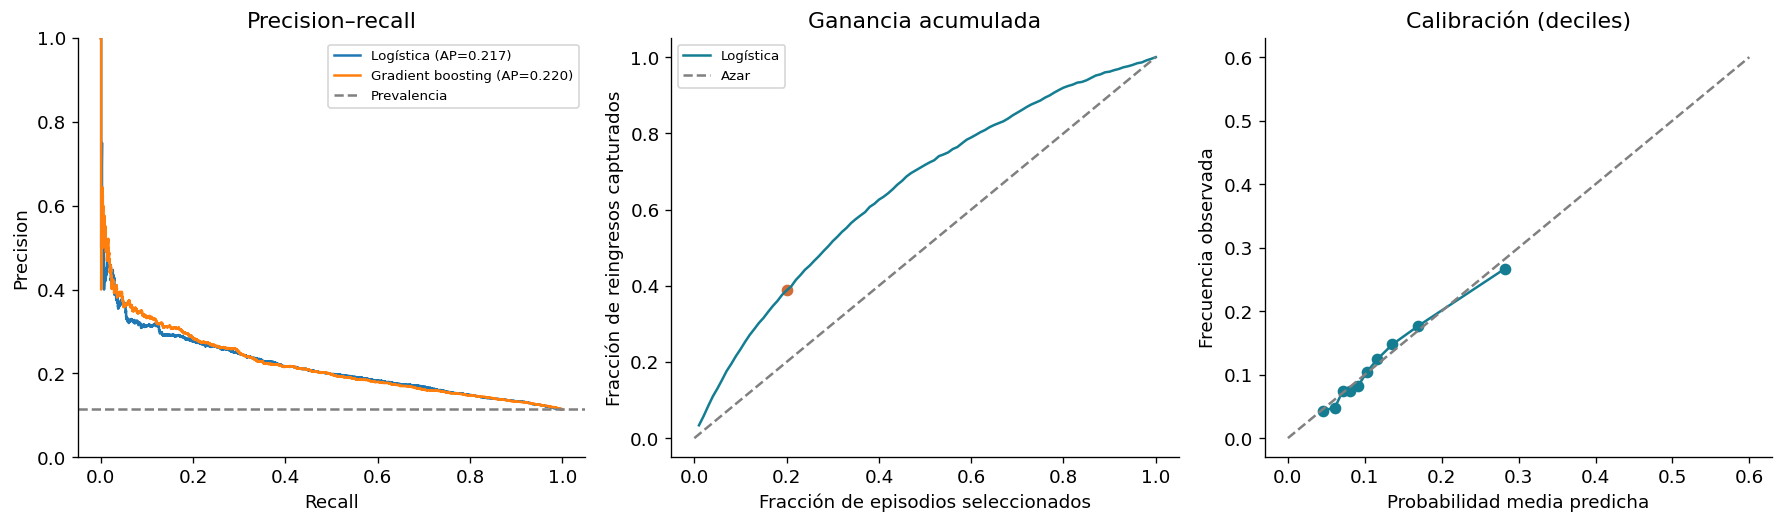

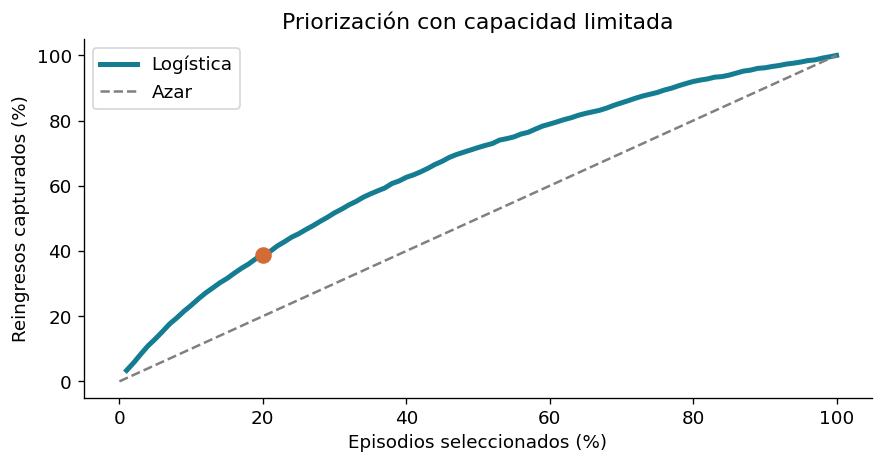

In [10]:
fig, axes = plt.subplots(1,3,figsize=(15,4.5))
for name in ['Logística','Gradient boosting']:
    pr,rec,_ = precision_recall_curve(yte,test_probs[name])
    axes[0].plot(rec,pr,label=f"{name} (AP={test_scores[name]['AP']:.3f})")
axes[0].axhline(yte.mean(),color='gray',linestyle='--',label='Prevalencia')
axes[0].set(xlabel='Recall',ylabel='Precision',title='Precision–recall',ylim=(0,1))
axes[0].legend(fontsize=8)
qgrid = np.linspace(.01,1,100)
gains = [top_metrics(yte,pbest,q)['recall'] for q in qgrid]
axes[1].plot(qgrid,gains,color='#147D92',label=selected_name)
axes[1].plot([0,1],[0,1],'--',color='gray',label='Azar')
axes[1].scatter([.20],[operating['recall']],color='#D36B36')
axes[1].set(xlabel='Fracción de episodios seleccionados',ylabel='Fracción de reingresos capturados',title='Ganancia acumulada')
axes[1].legend(fontsize=8)
fr, mp = calibration_curve(yte,pbest,n_bins=10,strategy='quantile')
axes[2].plot(mp,fr,'o-',color='#147D92')
axes[2].plot([0,.6],[0,.6],'--',color='gray')
axes[2].set(xlabel='Probabilidad media predicha',ylabel='Frecuencia observada',title='Calibración (deciles)')
fig.tight_layout(); fig.savefig(OUT/'evaluacion.png',dpi=170); plt.show()
fig,ax = plt.subplots(figsize=(7.5,4))
ax.plot(qgrid*100,np.array(gains)*100,lw=3,color='#147D92',label=selected_name)
ax.plot([0,100],[0,100],'--',color='gray',label='Azar')
ax.scatter([20],[operating['recall']*100],s=80,color='#D36B36',zorder=4)
ax.set(xlabel='Episodios seleccionados (%)',ylabel='Reingresos capturados (%)',title='Priorización con capacidad limitada')
ax.legend(); fig.tight_layout(); fig.savefig(OUT/'ganancia.png',dpi=170); plt.show()

## 7. Sensibilidades y límites
Se evalúa el modelo congelado en altas a domicilio (códigos 1, 6, 8). Es un análisis descriptivo posterior, no validación externa. También se muestran métricas por sexo y edad, sin afirmar equidad a partir de diferencias puntuales.

Los diagnósticos y la medicación pueden contener señales de severidad o de prácticas asistenciales. Ni la importancia de una feature ni una ablación establecen efectos causales. Las intervenciones para reducir reingresos requieren otro diseño de evaluación.

In [11]:
home = cohort.iloc[test_idx].discharge_disposition_id.isin([1,6,8]).to_numpy()
home_scores = {'episodios': int(home.sum()), 'prevalencia': float(ya[home].mean()),
               **metrics(ya[home],pbest[home])}
print('Sensibilidad en altas a domicilio:'); display(pd.Series(home_scores).to_frame('valor'))
subgroups = []
ct = cohort.iloc[test_idx].reset_index(drop=True)
for col in ['gender','age']:
    for value in sorted(ct[col].unique()):
        mask = ct[col].eq(value).to_numpy()
        if mask.sum() >= 200 and ya[mask].sum() >= 20:
            subgroups.append({'variable': col, 'grupo': value, 'n': int(mask.sum()),
                              'prevalencia': float(ya[mask].mean()),
                              'AUROC': roc_auc_score(ya[mask],pbest[mask]),
                              'AP': average_precision_score(ya[mask],pbest[mask])})
display(pd.DataFrame(subgroups).round(4))

Sensibilidad en altas a domicilio:


,valor
episodios,14561.000000
prevalencia,0.100474
AUROC,0.665142
AP,0.196461
Brier,0.087065
Precision@20,0.196361
Recall@20,0.390977
Lift@20,1.954350


,variable,grupo,n,prevalencia,AUROC,AP
0,gender,Female,10470,0.1147,0.6852,0.2180
1,gender,Male,9301,0.1138,0.6568,0.2165
2,age,[20-30),336,0.1339,0.7544,0.3078
3,age,[30-40),710,0.1085,0.7161,0.2410
4,age,[40-50),2007,0.1071,0.7112,0.2440
5,age,[50-60),3378,0.1033,0.7148,0.2593
6,age,[60-70),4472,0.1163,0.6548,0.2024
7,age,[70-80),5025,0.1186,0.6639,0.2299
8,age,[80-90),3350,0.1182,0.6303,0.1771
9,age,[90-100),493,0.1237,0.5542,0.1763


## 8. Exportación reproducible y conclusión
Los resultados guardados alimentan el informe y la presentación. `split_assignments.csv` permite auditar que ningún paciente cruza particiones. No se exportan modelos serializados: el notebook reconstruye los estimadores con las versiones registradas.

In [12]:
split_summary = [{'particion': k, 'episodios': len(ix), 'pacientes': int(groups.iloc[ix].nunique()),
                  'positivos': int(y.iloc[ix].sum()), 'prevalencia': float(y.iloc[ix].mean())}
                 for k,ix in parts.items()]
result = {'fecha': '2026-10-02', 'seed': SEED, 'versions': versions, 'sha256_zip': sha256,
          'source_url': URL, 'cohort_flow': flow, 'cohort_n': len(cohort),
          'cohort_patients': int(groups.nunique()), 'cohort_prevalence': float(y.mean()),
          'features': X.columns.tolist(), 'excluded_features': excluded+dropped,
          'splits': split_summary, 'validation': validation_scores,
          'diagnostics_validation': diagnostics, 'selected_model': selected_name,
          'test': test_scores, 'test_prevalence': float(yte.mean()),
          'operating_top20': operating, 'ci95': ci.to_dict('index'),
          'feasible': feasible, 'home_sensitivity': home_scores,
          'fit_seconds': fit_seconds,
          'importance_validation': importance.head(12).to_dict('records'),
          'gain_curve': {'capacity': qgrid.tolist(), 'recall': gains},
          'subgroups': subgroups}
(OUT/'results.json').write_text(json.dumps(result,indent=2,ensure_ascii=False),encoding='utf-8')
test_table.to_csv(OUT/'metricas_test.csv',index_label='modelo')
importance.to_csv(OUT/'importancia_validacion.csv',index=False)
capacity.to_csv(OUT/'capacidad_seguimiento.csv',index=False)
ci.to_csv(OUT/'intervalos_bootstrap.csv',index_label='metrica')
assign = pd.concat([cohort.iloc[ix][['encounter_id','patient_nbr']].assign(partition=k) for k,ix in parts.items()])
assign.to_csv(OUT/'split_assignments.csv',index=False)
display(pd.DataFrame(split_summary))
print(f"{'Hay' if feasible else 'No hay suficiente'} señal para continuar esta PoC bajo el criterio fijado.")
print(f"AP: {test_scores[selected_name]['AP']:.3f}, referencia: {yte.mean():.3f}.")
print(f"Top 20%: recall {operating['recall']:.1%}, precision {operating['precision']:.1%}, lift {operating['lift']:.2f}x.")
print('La conclusión se limita a esta cohorte histórica y a este diseño retrospectivo.')

,particion,episodios,pacientes,positivos,prevalencia
0,train,58870,41586,6758,0.114795
1,validation,19849,13862,2254,0.113557
2,test,19771,13863,2259,0.114258


Hay señal para continuar esta PoC bajo el criterio fijado.
AP: 0.217, referencia: 0.114.
Top 20%: recall 38.8%, precision 22.1%, lift 1.94x.
La conclusión se limita a esta cohorte histórica y a este diseño retrospectivo.


## 9. Próxima iteración
1. Repetir validación por grupos con varias semillas o validación cruzada anidada, manteniendo una nueva reserva final intacta. Este test ya fue consultado y no debe convertirse en conjunto de ajuste.
2. Revisar con el equipo docente la cohorte y el significado de cada campo al alta, incluyendo transferencias, medicación y observabilidad del seguimiento.
3. Evaluar calibración sobre validación y seleccionar capacidad/umbral con un criterio operativo explícito. Analizar errores, incertidumbre por subgrupo y costos de falsas alertas.
4. Para una afirmación clínica o local, conseguir validación temporal/externa y evaluar si el seguimiento propuesto realmente mejora resultados.

**Limitaciones de esta PoC:** datos de EE. UU. de 1999–2008; no hay fechas ni identificador hospitalario adecuados para validación temporal/por centro; captura incompleta de reingresos externos y seguimiento; posibles diferencias de codificación; predicción de cualquier causa, no evitabilidad; separación por paciente no elimina todos los sesgos de selección. El bootstrap no incorpora variación por reentrenar el modelo ni por cambiar el split.

## Referencias
- Clore et al. (2014). UCI Diabetes 130-US Hospitals. https://doi.org/10.24432/C5230J. CC BY 4.0.
- Strack et al. (2014). *Impact of HbA1c Measurement on Hospital Readmission Rates: Analysis of 70,000 Clinical Database Patient Records*. https://doi.org/10.1155/2014/781670.
- Diccionario de destinos/orígenes: `IDS_mapping.csv`, incluido en la descarga de UCI.
- Resultados y gráficos: ejecución propia de este notebook. No usar métricas publicadas como si fueran resultados de esta ejecución.